In [2]:
# ============================================================
# IMPORTAÇÃO DO DATASET - GOOGLE COLAB
# Caso esteja usando um ambiente virtual local esse bloco pode ser ignorado
# ============================================================

from google.colab import files
from pathlib import Path
import shutil

# Cria a pasta data, caso ela não exista
DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Abre a janela para selecionar o arquivo CSV
uploaded = files.upload()

# Procura o arquivo CSV enviado
csv_files = [filename for filename in uploaded if filename.lower().endswith(".csv")]

if not csv_files:
    raise FileNotFoundError("Nenhum arquivo CSV foi enviado.")

# Utiliza o primeiro CSV enviado
uploaded_file = Path(csv_files[0])

# Copia o arquivo para a pasta data com o nome esperado pelo projeto
DATA_PATH = DATA_DIR / "manutencao_preditiva.csv"
shutil.copy(uploaded_file, DATA_PATH)

print(f"Arquivo importado com sucesso: {DATA_PATH}")

Saving manutencao_preditiva.csv to manutencao_preditiva.csv
Arquivo importado com sucesso: data/manutencao_preditiva.csv


# Projeto Avaliativo — Pipeline Preditivo de Manutenção

## Previsão de falhas mecânicas em equipamentos industriais

Este notebook implementa um pipeline completo de Ciência de Dados para prever a variável `falha_maquina`.

**Objetivo:** comparar KNN e Árvore de Decisão e selecionar o modelo com melhor desempenho no conjunto de teste, considerando também sinais de overfitting.

### Estrutura
1. Análise Exploratória (EDA)
2. Limpeza e Tratamento de Dados
3. Feature Engineering
4. Divisão e Balanceamento
5. Escalonamento das Variáveis
6. Ajuste de Parâmetros e Overfitting
7. Avaliação da Acurácia e Veredito Final

> As colunas `falha_twf`, `falha_hdf`, `falha_pwf`, `falha_osf` e `falha_rnf` são motivos técnicos da falha e não são utilizadas como preditoras, conforme as anotações do Departamento de Engenharia.


In [3]:
# Bibliotecas
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from imblearn.over_sampling import SMOTENC

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

RANDOM_STATE = 42
DATA_PATH = Path("data") / "manutencao_preditiva.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dimensões da base: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head()


Dimensões da base: 10000 linhas x 14 colunas


,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1000,308.6000,1551.0000,42.8000,0,0,0,0,0,0,0
1,2,L47181,L,298.2000,308.7000,1408.0000,46.3000,3,0,0,0,0,0,0
2,3,L47182,L,298.1000,308.5000,1498.0000,49.4000,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2000,308.7000,1408.0000,40.0000,9,0,0,0,0,0,0


## 1. Análise Exploratória (EDA)

A base possui 10.000 registros e 14 colunas. O mapeamento das variáveis indica que `falha_maquina` é a variável-alvo. `udi` é identificador, `id_produto` é identificador textual e as cinco colunas de motivo de falha devem ficar fora do conjunto de preditores.


In [ ]:
# Tipos das variáveis
print("Tipos das variáveis:")
display(df.dtypes.to_frame("dtype"))

print("\nResumo estatístico das variáveis numéricas:")
display(df.describe())


Tipos das variáveis:


,dtype
udi,int64
id_produto,object
tipo,object
temperatura_ar_k,float64
temperatura_processo_k,float64
velocidade_rotacao_rpm,float64
torque_nm,float64
desgaste_ferramenta_min,int64
falha_maquina,int64
falha_twf,int64



Resumo estatístico das variáveis numéricas:


,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.0000,9500.0000,9500.0000,9500.0000,9500.0000,10000.0000,10000.0000,10000.0000,10000.0000,10000.0000,10000.0000,10000.0000
mean,5000.5000,300.0022,310.0009,1539.2453,39.9742,107.9510,0.0339,0.0046,0.0115,0.0095,0.0098,0.0019
std,2886.8957,2.0017,1.4864,180.2736,9.9955,63.6541,0.1810,0.0677,0.1066,0.0970,0.0985,0.0435
min,1.0000,295.3000,305.7000,1168.0000,3.8000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,2500.7500,298.3000,308.8000,1423.0000,33.1000,53.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
50%,5000.5000,300.1000,310.1000,1504.0000,40.1000,108.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
75%,7500.2500,301.5000,311.1000,1613.0000,46.7000,162.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
max,10000.0000,304.5000,313.8000,2886.0000,76.6000,253.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


In [ ]:
# Valores ausentes e duplicidades
print("Valores ausentes por coluna:")
display(df.isna().sum().to_frame("nulos").sort_values("nulos", ascending=False))

print(f"\nQuantidade de linhas duplicadas: {df.duplicated().sum()}")

print("\nDistribuição da variável alvo:")
target_dist = df["falha_maquina"].value_counts().sort_index()
target_pct = df["falha_maquina"].value_counts(normalize=True).sort_index().mul(100)
display(pd.DataFrame({"quantidade": target_dist, "percentual": target_pct}))


Valores ausentes por coluna:


,nulos
temperatura_processo_k,500
temperatura_ar_k,500
velocidade_rotacao_rpm,500
torque_nm,500
id_produto,0
udi,0
tipo,0
desgaste_ferramenta_min,0
falha_maquina,0
falha_twf,0



Quantidade de linhas duplicadas: 0

Distribuição da variável alvo:


,quantidade,percentual
falha_maquina,,
0,9661,96.6100
1,339,3.3900


### Gráfico 1 — Distribuição da variável alvo

A variável-alvo é desbalanceada: a classe 0 representa a grande maioria dos registros e a classe 1 é minoritária. Esse cenário é importante porque uma divisão aleatória sem estratificação pode alterar a proporção entre treino e teste. Por isso, será utilizado `stratify=y` e, posteriormente, uma técnica de reamostragem somente no conjunto de treinamento.


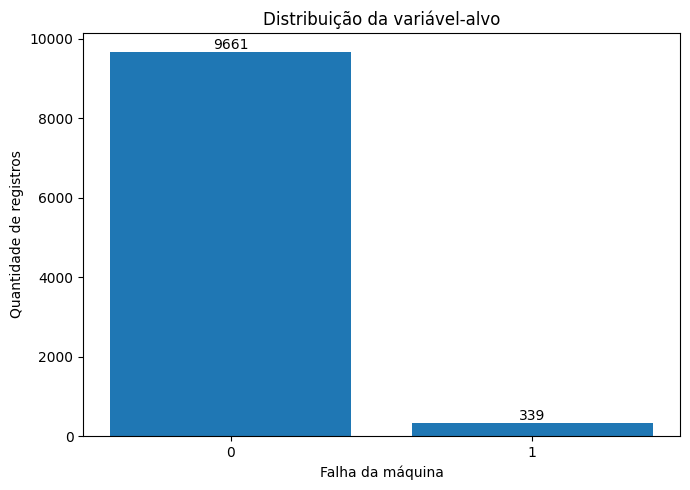

In [ ]:
# Gráfico 1: balanceamento da variável alvo
plt.figure(figsize=(7, 5))
counts = df["falha_maquina"].value_counts().sort_index()
ax = plt.bar(counts.index.astype(str), counts.values)
plt.title("Distribuição da variável-alvo")
plt.xlabel("Falha da máquina")
plt.ylabel("Quantidade de registros")

for bar in ax:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{int(bar.get_height())}", ha="center", va="bottom")

plt.tight_layout()
plt.show()


### Gráfico 2 — Distribuição do torque

O torque apresenta dispersão considerável e alguns valores elevados. Como os valores extremos podem influenciar a média, a mediana será utilizada na imputação dos dados ausentes.


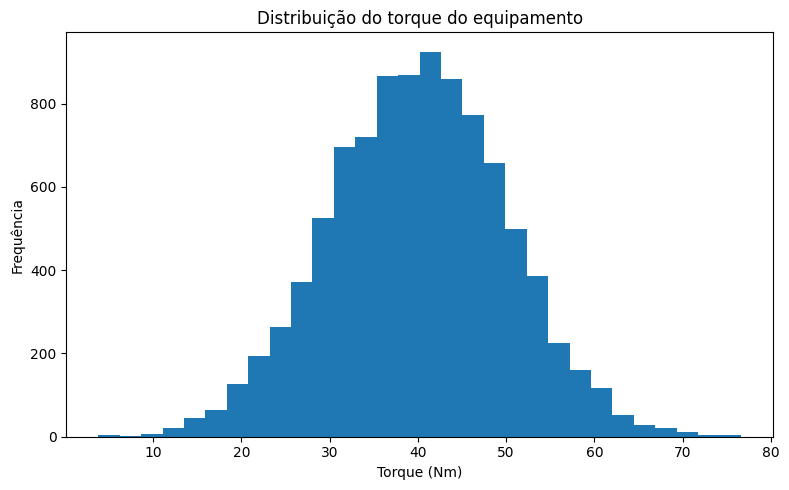

In [ ]:
# Gráfico 2: distribuição do torque
plt.figure(figsize=(8, 5))
plt.hist(df["torque_nm"].dropna(), bins=30)
plt.title("Distribuição do torque do equipamento")
plt.xlabel("Torque (Nm)")
plt.ylabel("Frequência")
plt.tight_layout()
plt.show()


### Gráfico 3 — Correlação de Pearson

A correlação com `falha_maquina` é apenas uma indicação exploratória e não determina sozinha quais variáveis serão usadas. O modelo terá acesso às variáveis operacionais definidas no mapeamento do projeto.


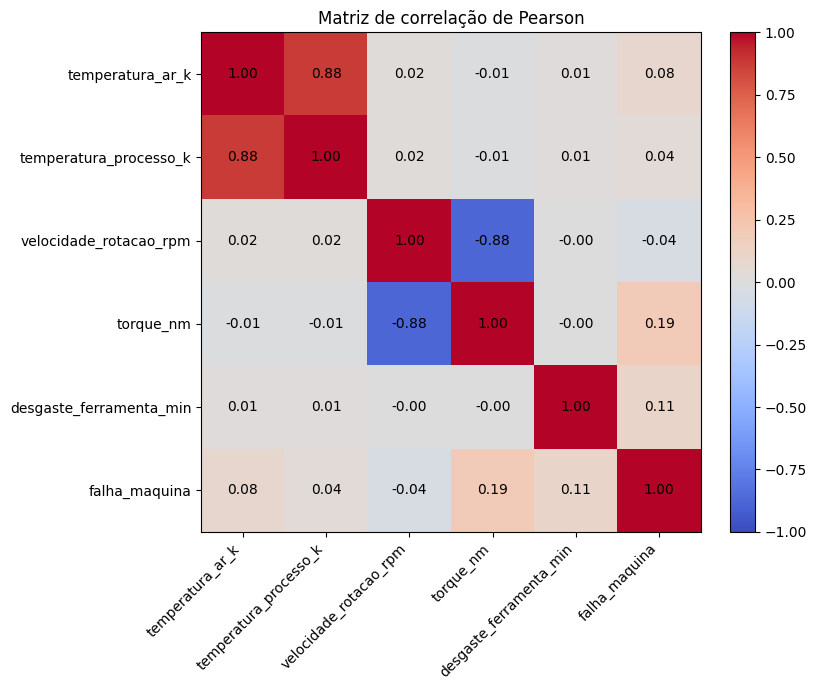

Correlação das variáveis numéricas com a variável-alvo:


,correlacao
falha_maquina,1.0000
torque_nm,0.1889
desgaste_ferramenta_min,0.1054
temperatura_ar_k,0.0831
temperatura_processo_k,0.0375
velocidade_rotacao_rpm,-0.0408


In [ ]:
numeric_cols = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
]

corr = df[numeric_cols + ["falha_maquina"]].corr()

plt.figure(figsize=(9, 7))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Matriz de correlação de Pearson")
plt.tight_layout()
plt.show()

print("Correlação das variáveis numéricas com a variável-alvo:")
display(corr["falha_maquina"].sort_values(ascending=False).to_frame("correlacao"))


## 2. Limpeza e Tratamento de Dados

Não foram encontradas linhas duplicadas. Foram identificados 500 registros com valores ausentes nas quatro variáveis contínuas de operação (`temperatura_ar_k`, `temperatura_processo_k`, `velocidade_rotacao_rpm` e `torque_nm`).

A imputação será feita pela **mediana**, por ser uma medida robusta à presença de valores extremos, especialmente em velocidade de rotação e torque. Para evitar vazamento de informação, a mediana será calculada exclusivamente no conjunto de treino e depois aplicada ao conjunto de teste.

Os outliers serão identificados por boxplots, mas não serão automaticamente removidos: valores extremos de operação podem representar condições reais de funcionamento e também podem carregar informação preditiva.


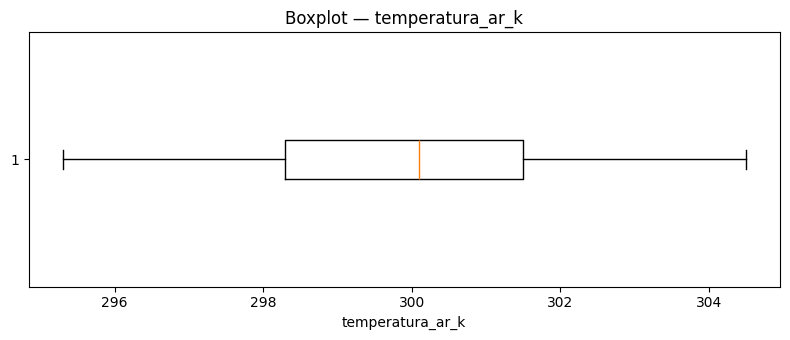

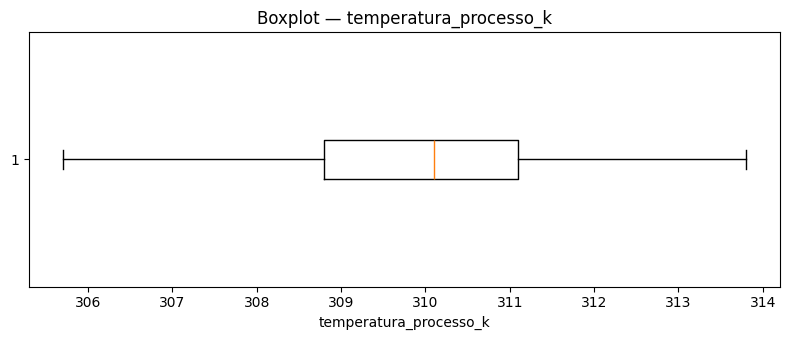

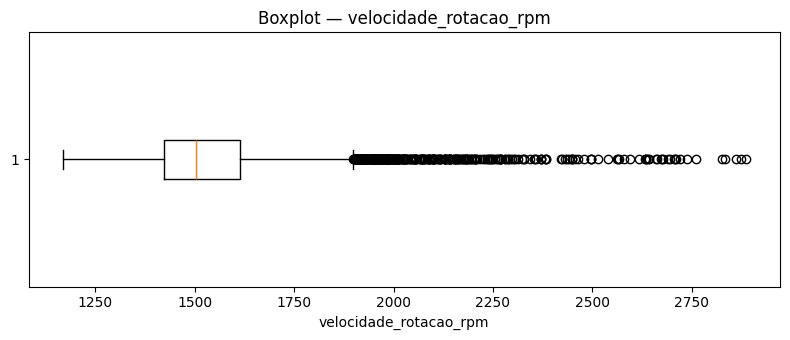

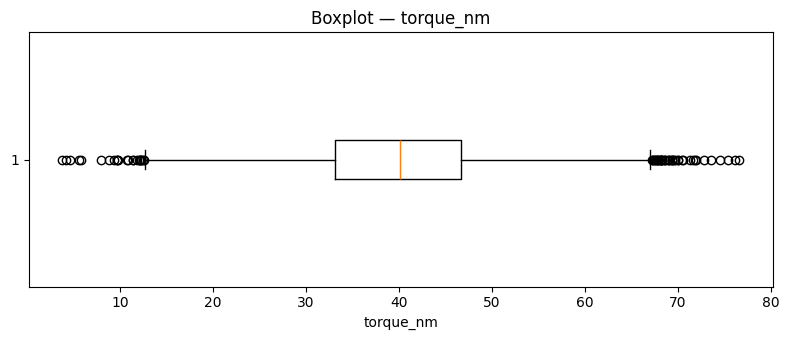

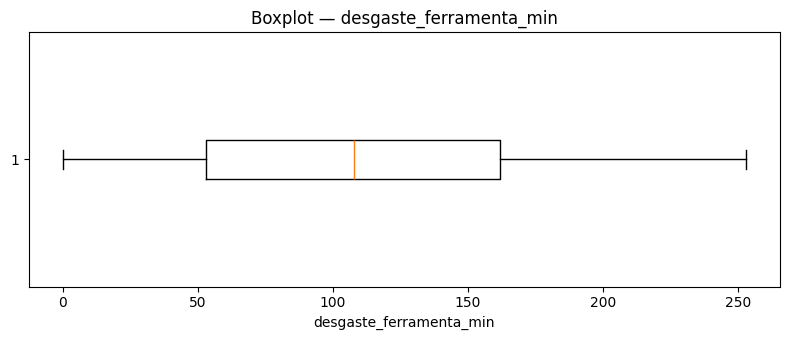

,variavel,Q1,Q3,limite_inferior,limite_superior,qtd_outliers
0,temperatura_ar_k,298.3000,301.5000,293.5000,306.3000,0
1,temperatura_processo_k,308.8000,311.1000,305.3500,314.5500,0
2,velocidade_rotacao_rpm,1423.0000,1613.0000,1138.0000,1898.0000,398
3,torque_nm,33.1000,46.7000,12.7000,67.1000,63
4,desgaste_ferramenta_min,53.0000,162.0000,-110.5000,325.5000,0


In [ ]:
# Boxplots para análise de outliers
fig_cols = numeric_cols

for col in fig_cols:
    plt.figure(figsize=(8, 3.5))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(f"Boxplot — {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

# Contagem de outliers pelo critério IQR
outlier_summary = []

for col in numeric_cols:
    series = df[col].dropna()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((series < lower) | (series > upper)).sum()
    outlier_summary.append([col, q1, q3, lower, upper, int(count)])

outlier_summary = pd.DataFrame(
    outlier_summary,
    columns=["variavel", "Q1", "Q3", "limite_inferior", "limite_superior", "qtd_outliers"]
)

display(outlier_summary)


## 3. Feature Engineering

Será criada a variável `potencia`, conforme a sugestão do enunciado:

`potencia = velocidade_rotacao_rpm × torque_nm`

Os valores ausentes serão tratados antes da operação. A variável representa uma combinação entre a velocidade de rotação e o torque, acrescentando ao modelo uma medida operacional derivada.


In [ ]:
# Definição das variáveis
target = "falha_maquina"

# Identificadores e motivos técnicos de falha não entram em X.
excluded_cols = [
    "udi",
    "id_produto",
    "falha_twf",
    "falha_hdf",
    "falha_pwf",
    "falha_osf",
    "falha_rnf",
]

feature_cols = ["tipo"] + numeric_cols

X_raw = df[feature_cols].copy()
y = df[target].copy()

print("Preditores considerados:")
print(feature_cols)


Preditores considerados:
['tipo', 'temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min']


## 4. Divisão e Balanceamento dos Dados

A base será dividida em 80% para treino e 20% para teste, utilizando `stratify=y`.

O balanceamento será aplicado **somente ao treino**. Como `tipo` é uma variável categórica, será utilizado `SMOTENC`, uma variante do SMOTE adequada para conjuntos com atributos categóricos. Assim, evita-se gerar valores artificiais inadequados para a categoria `tipo`.

O conjunto de teste permanece com sua distribuição original, pois representa a situação real em que o modelo será avaliado.


In [ ]:
# Divisão estratificada
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Treino:", X_train_raw.shape, "Teste:", X_test_raw.shape)
print("\nDistribuição do alvo no treino:")
display(y_train.value_counts().sort_index().to_frame("quantidade"))
print("\nDistribuição do alvo no teste:")
display(y_test.value_counts().sort_index().to_frame("quantidade"))


Treino: (8000, 6) Teste: (2000, 6)

Distribuição do alvo no treino:


,quantidade
falha_maquina,
0,7729
1,271



Distribuição do alvo no teste:


,quantidade
falha_maquina,
0,1932
1,68


In [ ]:
# Imputação sem vazamento: mediana calculada somente no treino
imputer = SimpleImputer(strategy="median")

X_train_num = pd.DataFrame(
    imputer.fit_transform(X_train_raw[numeric_cols]),
    columns=numeric_cols,
    index=X_train_raw.index,
)

X_test_num = pd.DataFrame(
    imputer.transform(X_test_raw[numeric_cols]),
    columns=numeric_cols,
    index=X_test_raw.index,
)

# Feature engineering após o tratamento dos nulos
X_train_num["potencia"] = (
    X_train_num["velocidade_rotacao_rpm"] * X_train_num["torque_nm"]
)

X_test_num["potencia"] = (
    X_test_num["velocidade_rotacao_rpm"] * X_test_num["torque_nm"]
)

# Codificação categórica para SMOTENC
categorias = sorted(X_raw["tipo"].dropna().unique())
cat_mapping = {categoria: i for i, categoria in enumerate(categorias)}

X_train_model = X_train_num.copy()
X_test_model = X_test_num.copy()

X_train_model["tipo"] = X_train_raw["tipo"].map(cat_mapping).astype(int).values
X_test_model["tipo"] = X_test_raw["tipo"].map(cat_mapping).astype(int).values

print("Valores nulos após imputação:")
print(X_train_model.isna().sum().sum(), "no treino")
print(X_test_model.isna().sum().sum(), "no teste")


Valores nulos após imputação:
0 no treino
0 no teste


In [ ]:
# Balanceamento somente no treino
tipo_index = X_train_model.columns.get_loc("tipo")

smotenc = SMOTENC(
    categorical_features=[tipo_index],
    random_state=RANDOM_STATE,
)

X_train_balanced, y_train_balanced = smotenc.fit_resample(
    X_train_model,
    y_train,
)

X_train_balanced = pd.DataFrame(
    X_train_balanced,
    columns=X_train_model.columns,
)

y_train_balanced = pd.Series(
    y_train_balanced,
    name=target,
)

print("Distribuição antes do balanceamento:")
display(y_train.value_counts().sort_index().to_frame("quantidade"))

print("Distribuição depois do SMOTENC:")
display(y_train_balanced.value_counts().sort_index().to_frame("quantidade"))


Distribuição antes do balanceamento:


,quantidade
falha_maquina,
0,7729
1,271


Distribuição depois do SMOTENC:


,quantidade
falha_maquina,
0,7729
1,7729


## Preparação final das variáveis

A variável `tipo` será transformada em variáveis indicadoras (`one-hot encoding`).

Para o KNN, somente as variáveis contínuas serão escalonadas com `StandardScaler`. As variáveis categóricas codificadas permanecem sem escalonamento.

A Árvore de Decisão será treinada sem `StandardScaler`, pois suas decisões são baseadas em regras de divisão dos atributos e não dependem da escala numérica.


In [ ]:
# One-hot encoding da variável tipo
X_train_balanced["tipo"] = X_train_balanced["tipo"].round().astype(int)
X_test_model["tipo"] = X_test_model["tipo"].round().astype(int)

X_train_balanced["tipo"] = X_train_balanced["tipo"].map({v: k for k, v in cat_mapping.items()})
X_test_model["tipo"] = X_test_model["tipo"].map({v: k for k, v in cat_mapping.items()})

X_train_cat = pd.get_dummies(
    X_train_balanced[["tipo"]],
    prefix="tipo",
    dtype=int,
)

X_test_cat = pd.get_dummies(
    X_test_model[["tipo"]],
    prefix="tipo",
    dtype=int,
).reindex(columns=X_train_cat.columns, fill_value=0)

continuous_cols = numeric_cols + ["potencia"]

X_train_final = pd.concat(
    [X_train_balanced[continuous_cols], X_train_cat],
    axis=1,
)

X_test_final = pd.concat(
    [X_test_model[continuous_cols], X_test_cat],
    axis=1,
)

print("Variáveis finais:")
print(X_train_final.columns.tolist())


Variáveis finais:
['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min', 'potencia', 'tipo_H', 'tipo_L', 'tipo_M']


In [ ]:
# StandardScaler somente nas variáveis contínuas para o KNN
scaler = StandardScaler()

X_train_knn = X_train_final.copy()
X_test_knn = X_test_final.copy()

X_train_knn[continuous_cols] = scaler.fit_transform(
    X_train_final[continuous_cols]
)

X_test_knn[continuous_cols] = scaler.transform(
    X_test_final[continuous_cols]
)

print("Escalonamento concluído para o KNN.")


Escalonamento concluído para o KNN.


## 6. Ajuste de Parâmetros e Combate ao Overfitting

Serão avaliados diferentes valores de `n_neighbors` no KNN e diferentes valores de `max_depth` na Árvore de Decisão.

A comparação entre acurácia de treino e teste será utilizada para identificar configurações que decoram excessivamente os dados de treino.


In [ ]:
# Avaliação de diferentes valores de K
knn_results = []

for k in [3, 5, 7, 9, 11]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_knn, y_train_balanced)

    train_acc = accuracy_score(
        y_train_balanced,
        model.predict(X_train_knn),
    )
    test_acc = accuracy_score(
        y_test,
        model.predict(X_test_knn),
    )

    knn_results.append([k, train_acc, test_acc])

knn_results = pd.DataFrame(
    knn_results,
    columns=["K", "acuracia_treino", "acuracia_teste"],
)

display(knn_results)


,K,acuracia_treino,acuracia_teste
0,3,0.9656,0.9090
1,5,0.9538,0.8985
2,7,0.9458,0.8905
3,9,0.9409,0.8875
4,11,0.9373,0.8865


In [ ]:
# Avaliação de diferentes profundidades da árvore
tree_results = []

for depth in [3, 5, 8, 10, None]:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=RANDOM_STATE,
    )
    model.fit(X_train_final, y_train_balanced)

    train_acc = accuracy_score(
        y_train_balanced,
        model.predict(X_train_final),
    )
    test_acc = accuracy_score(
        y_test,
        model.predict(X_test_final),
    )

    tree_results.append([
        "None" if depth is None else depth,
        train_acc,
        test_acc,
    ])

tree_results = pd.DataFrame(
    tree_results,
    columns=["max_depth", "acuracia_treino", "acuracia_teste"],
)

display(tree_results)


,max_depth,acuracia_treino,acuracia_teste
0,3,0.8629,0.8645
1,5,0.9040,0.9080
2,8,0.9261,0.9225
3,10,0.9451,0.9155
4,None,0.9995,0.9300


### Interpretação do overfitting

No KNN, valores menores de `K` tendem a produzir maior acurácia no treino e podem aumentar a sensibilidade a ruído. A comparação treino/teste permite observar esse comportamento.

Na Árvore, a configuração sem limite de profundidade tende a aumentar bastante a acurácia de treino, sendo um sinal clássico de sobreajuste. Uma profundidade intermediária oferece um compromisso melhor entre desempenho e estabilidade.


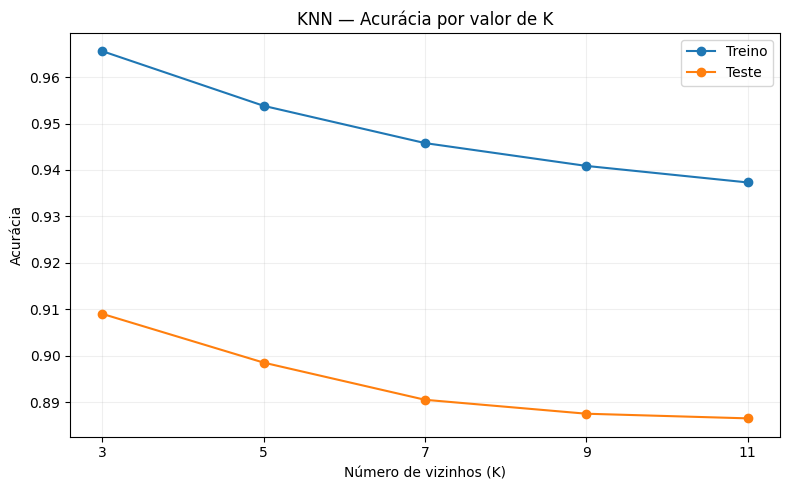

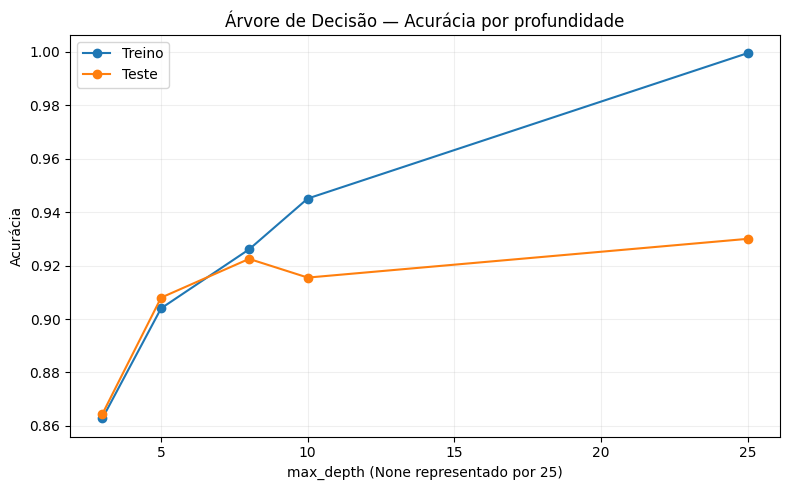

In [ ]:
# Visualização treino x teste — KNN
plt.figure(figsize=(8, 5))
plt.plot(knn_results["K"], knn_results["acuracia_treino"], marker="o", label="Treino")
plt.plot(knn_results["K"], knn_results["acuracia_teste"], marker="o", label="Teste")
plt.title("KNN — Acurácia por valor de K")
plt.xlabel("Número de vizinhos (K)")
plt.ylabel("Acurácia")
plt.xticks(knn_results["K"])
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Visualização treino x teste — Árvore
tree_plot = tree_results.copy()
tree_plot["depth_plot"] = tree_plot["max_depth"].map(lambda x: 25 if x == "None" else int(x))

plt.figure(figsize=(8, 5))
plt.plot(tree_plot["depth_plot"], tree_plot["acuracia_treino"], marker="o", label="Treino")
plt.plot(tree_plot["depth_plot"], tree_plot["acuracia_teste"], marker="o", label="Teste")
plt.title("Árvore de Decisão — Acurácia por profundidade")
plt.xlabel("max_depth (None representado por 25)")
plt.ylabel("Acurácia")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 7. Avaliação da Acurácia e Veredito Final

O melhor KNN será definido pela maior acurácia no teste. Para a Árvore de Decisão, a maior acurácia de teste será registrada, mas também será observada a diferença entre treino e teste para evitar escolher uma configuração excessivamente ajustada ao treino.

A conclusão final considera tanto a métrica solicitada no projeto quanto a estabilidade do modelo.


In [ ]:
# Melhor configuração de cada família pelo teste
best_knn_row = knn_results.loc[knn_results["acuracia_teste"].idxmax()]
best_knn_k = int(best_knn_row["K"])

best_tree_row = tree_results.loc[tree_results["acuracia_teste"].idxmax()]
best_tree_depth = None if best_tree_row["max_depth"] == "None" else int(best_tree_row["max_depth"])

best_knn = KNeighborsClassifier(n_neighbors=best_knn_k)
best_knn.fit(X_train_knn, y_train_balanced)

best_tree = DecisionTreeClassifier(
    max_depth=best_tree_depth,
    random_state=RANDOM_STATE,
)
best_tree.fit(X_train_final, y_train_balanced)

knn_test_acc = accuracy_score(y_test, best_knn.predict(X_test_knn))
tree_test_acc = accuracy_score(y_test, best_tree.predict(X_test_final))

comparison = pd.DataFrame({
    "modelo": [
        f"KNN (K={best_knn_k})",
        f"Árvore (max_depth={best_tree_depth})",
    ],
    "acuracia_teste": [knn_test_acc, tree_test_acc],
})

display(comparison)

print(f"Melhor KNN: K={best_knn_k} | acurácia de teste = {knn_test_acc:.4f}")
print(f"Melhor Árvore: max_depth={best_tree_depth} | acurácia de teste = {tree_test_acc:.4f}")


,modelo,acuracia_teste
0,KNN (K=3),0.9090
1,Árvore (max_depth=None),0.9300


Melhor KNN: K=3 | acurácia de teste = 0.9090
Melhor Árvore: max_depth=None | acurácia de teste = 0.9300


In [ ]:
# Relatório do modelo final por acurácia de teste
final_model_name = comparison.loc[
    comparison["acuracia_teste"].idxmax(),
    "modelo"
]

if tree_test_acc >= knn_test_acc:
    final_model = best_tree
    final_X_test = X_test_final
    final_prediction = best_tree.predict(X_test_final)
else:
    final_model = best_knn
    final_X_test = X_test_knn
    final_prediction = best_knn.predict(X_test_knn)

print("Modelo com maior acurácia de teste:", final_model_name)
print(f"Acurácia final: {accuracy_score(y_test, final_prediction):.4f}")

print("\nMatriz de confusão:")
display(pd.DataFrame(
    confusion_matrix(y_test, final_prediction),
    index=["Real 0", "Real 1"],
    columns=["Predito 0", "Predito 1"],
))

print("\nClassification report:")
print(classification_report(y_test, final_prediction, digits=4))


Modelo com maior acurácia de teste: Árvore (max_depth=None)
Acurácia final: 0.9300

Matriz de confusão:


,Predito 0,Predito 1
Real 0,1816,116
Real 1,24,44



Classification report:
              precision    recall  f1-score   support

           0     0.9870    0.9400    0.9629      1932
           1     0.2750    0.6471    0.3860        68

    accuracy                         0.9300      2000
   macro avg     0.6310    0.7935    0.6744      2000
weighted avg     0.9627    0.9300    0.9433      2000



### Conclusão

A variável-alvo apresenta forte desbalanceamento, com a classe de falha sendo minoritária. O pipeline utiliza divisão estratificada e balanceamento apenas no treino, preservando o conjunto de teste para uma avaliação mais realista.

A criação da variável `potencia` acrescenta uma informação derivada da interação entre velocidade de rotação e torque. O KNN exige escalonamento das variáveis contínuas, enquanto a Árvore de Decisão é treinada sem esse procedimento.

O modelo final deve ser escolhido com base na acurácia do teste, observando simultaneamente a diferença entre treino e teste. A configuração da árvore sem limite de profundidade pode alcançar uma acurácia de teste alta, mas apresenta maior risco de overfitting. Na execução com `random_state=42`, `max_depth=None` obteve a maior acurácia de teste entre as configurações avaliadas, enquanto `max_depth=8` apresentou desempenho próximo com uma diferença muito menor entre treino e teste. Assim, `max_depth=8` é uma alternativa mais estável quando o objetivo é reduzir o sobreajuste.


## Referência aos dados de engenharia

As anotações fornecidas pelo Departamento de Engenharia definem:
- `falha_maquina` como variável-alvo;
- `tipo` como categoria do equipamento;
- as unidades e significados das variáveis de temperatura, rotação, torque e desgaste;
- as colunas de motivos técnicos de falha como informações históricas que não devem ser utilizadas como preditores.

Essas definições foram utilizadas para selecionar e interpretar as variáveis do modelo.
